# Fase 3 — Modelado de tópicos por programa (UNISON)

Este notebook explora los tópicos descubiertos con **NMF sobre TF-IDF** en `src/data/fase3_topicos.py`. La unidad documental es la mención (`Enlace`, `Programa`) y el texto es el cuerpo de la nota. Se ajustaron 15 tópicos sobre 22,403 menciones de 129 programas. La coherencia NPMI media es 0.244 y cada programa conserva su top-3 de tópicos.

1. Definición de cada tópico y sus palabras clave.
2. Programas por tópico principal.
3. Mapa de calor programa × tópico (Top 20).
4. Perfil temático Pregrado vs. Posgrado.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

PROCESADO = Path('../data/processed').resolve()
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 140)

## 1. Definición de tópicos y programas con su tópico principal

In [2]:
topicos = pd.read_parquet(PROCESADO / 'topicos_programas.parquet')
definicion = pd.read_parquet(PROCESADO / 'topicos_definicion.parquet')
nivel = pd.read_parquet(PROCESADO / 'topicos_nivel.parquet')
resumen = pd.read_parquet(PROCESADO / 'resumen_pc2.parquet')

principal = topicos.loc[topicos.groupby('Programa')['Peso'].idxmax()].copy()
principal = principal.sort_values('Notas', ascending=False).reset_index(drop=True)

display(definicion)
display(
    principal.head(20)[
        ['Programa', 'Grupo', 'Notas', 'Tema_Num', 'Tema_Etiqueta', 'Peso_Porcentaje']
    ]
)

,Tema,Etiqueta,Palabras,Coherencia_NPMI
0,1,Sociedad y vida universitaria,ser / vida / cómo / rubio / sociedad / mujeres,0.0692
1,2,Premios y trayectorias,premio / trayectoria / estudiantil / rectora /...,0.2701
2,3,"Artes, música y danza",artes / música / danza / bellas / teatro / obra,0.3391
3,4,Salud y enfermería,salud / enfermería / medicina / módulos / aten...,0.2452
4,5,Admisión e ingreso,aspirantes / ingreso / examen / convocatoria /...,0.3934
5,6,Gobierno universitario,rector / ortega / romero / grijalva / montever...,0.3500
6,7,Alimentos y nutrición,alimentos / dipa / alimentación / radio / tiem...,0.3099
7,8,Calidad y evaluación educativa,acreditación / evaluación / calidad / consejo ...,0.2726
8,9,Eventos académicos,evento / conferencias / actividades / congreso...,0.1609
9,10,Egreso y graduación,ceremonia / egresados / generación / graduante...,0.3256


,Programa,Grupo,Notas,Tema_Num,Tema_Etiqueta,Peso_Porcentaje
0,Ingeniería Industrial y de Sistemas,Pregrado,1504,13,Ingeniería y tecnología,19.00
1,Licenciatura en Derecho,Pregrado,1112,14,Derecho y ciencias sociales,23.11
2,Licenciatura en Ciencias de la Comunicación,Pregrado,1025,14,Derecho y ciencias sociales,20.29
3,Ingeniería Civil,Pregrado,958,13,Ingeniería y tecnología,18.65
4,Ingeniería Química,Pregrado,818,13,Ingeniería y tecnología,25.68
5,Posgrado en Ciencias y Tecnología de Alimentos,Posgrado,752,7,Alimentos y nutrición,49.70
6,Licenciatura en Psicología,Pregrado,716,14,Derecho y ciencias sociales,19.42
7,Licenciatura en Música,Pregrado,712,3,"Artes, música y danza",51.32
8,Licenciatura en Artes,Pregrado,688,3,"Artes, música y danza",57.25
9,Licenciatura en Medicina,Pregrado,613,4,Salud y enfermería,19.39


## 2. Programas por tópico principal

Cuántos programas tienen cada tópico como su tema dominante.

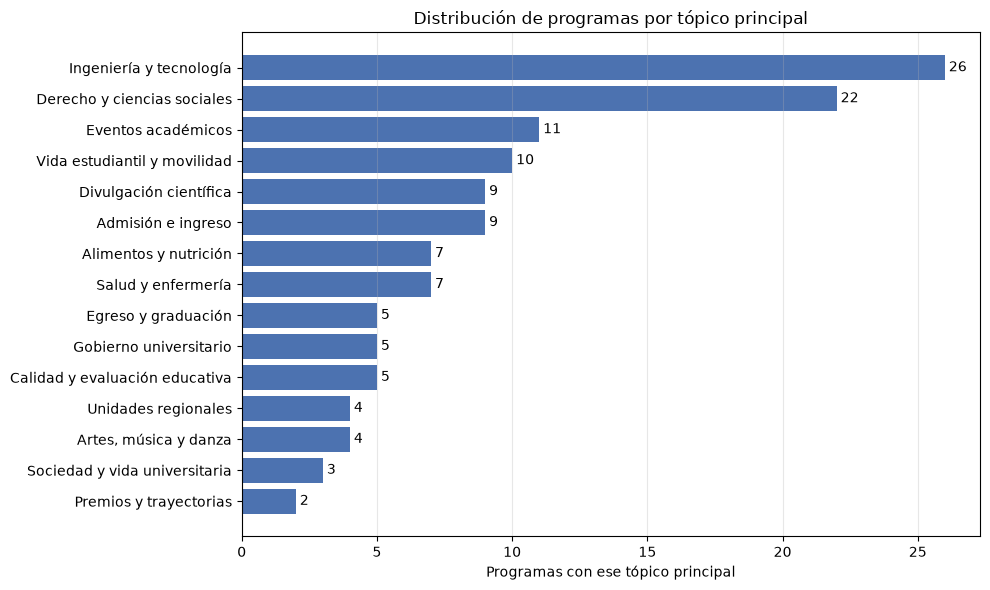

In [3]:
conteo = (
    principal.groupby(['Tema_Num', 'Tema_Etiqueta'])
    .size()
    .reset_index(name='Programas')
    .sort_values('Programas')
)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(conteo['Tema_Etiqueta'], conteo['Programas'], color='#4c72b0')
ax.set_xlabel('Programas con ese tópico principal')
ax.set_title('Distribución de programas por tópico principal')
ax.grid(axis='x', alpha=0.3)
for i, v in enumerate(conteo['Programas']):
    ax.text(v, i, f' {v}', va='center')
plt.tight_layout()
plt.show()

## 3. Mapa de calor programa × tópico (Top 20)

Participación de cada tópico en la carga temática del programa (%).

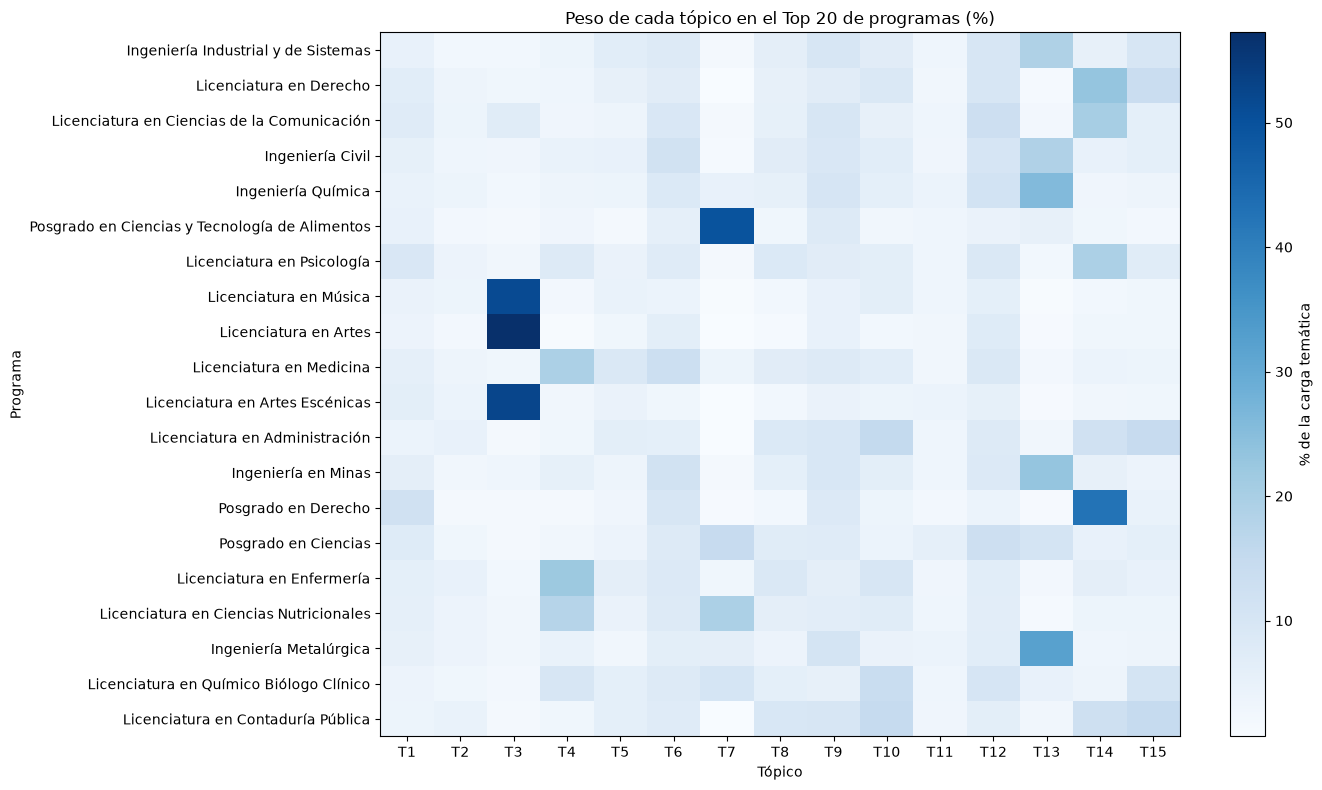

In [4]:
top = principal.head(20)['Programa'].tolist()
sub = topicos[topicos['Programa'].isin(top)]
pivot = (
    sub.pivot(index='Programa', columns='Tema_Num', values='Peso_Porcentaje')
    .loc[top]
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(pivot.values, aspect='auto', cmap='Blues')
ax.set_xticks(range(len(pivot.columns)), [f'T{c}' for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_xlabel('Tópico')
ax.set_ylabel('Programa')
ax.set_title('Peso de cada tópico en el Top 20 de programas (%)')
fig.colorbar(im, ax=ax, label='% de la carga temática')
plt.tight_layout()
plt.show()

## 4. Perfil temático Pregrado vs. Posgrado

Peso medio de cada tópico en las menciones de cada nivel.

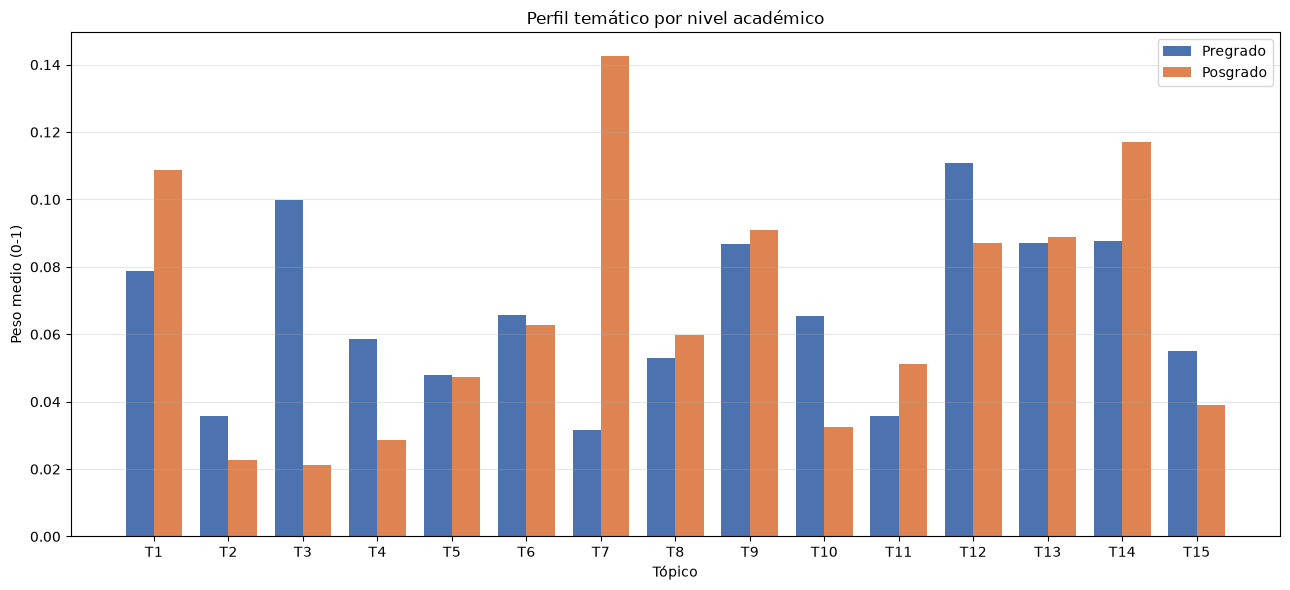

Grupo,Posgrado,Pregrado
Tema 1,0.109,0.079
Tema 2,0.023,0.036
Tema 3,0.021,0.100
Tema 4,0.029,0.058
Tema 5,0.047,0.048
Tema 6,0.063,0.066
Tema 7,0.142,0.032
Tema 8,0.060,0.053
Tema 9,0.091,0.087
Tema 10,0.032,0.065


In [5]:
piv = nivel.pivot(index='Tema_Num', columns='Grupo', values='Peso_Medio').fillna(0)
x = np.arange(len(piv))
ancho = 0.38
fig, ax = plt.subplots(figsize=(13, 6))
for i, grupo in enumerate(['Pregrado', 'Posgrado']):
    if grupo not in piv.columns:
        continue
    ax.bar(
        x + (i - 0.5) * ancho,
        piv[grupo],
        width=ancho,
        label=grupo,
        color=['#4c72b0', '#dd8452'][i],
    )
ax.set_xticks(x, [f'T{c}' for c in piv.index])
ax.set_xlabel('Tópico')
ax.set_ylabel('Peso medio (0-1)')
ax.set_title('Perfil temático por nivel académico')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

tabla = piv.copy()
tabla.index = [f'Tema {i}' for i in tabla.index]
display(tabla.round(3))

## 5. Capa B+: categorías temáticas

Taxonomía fija de 19 categorías más `Otros`, clasificada por similitud coseno entre el TF-IDF de cada nota y las descripciones (umbral 0.03).

In [6]:
categorias_def = pd.read_parquet(PROCESADO / 'categorias_definicion.parquet')
categorias_prog = pd.read_parquet(PROCESADO / 'categorias_programas.parquet')

display(categorias_def[['Categoria', 'Notas', 'Porcentaje']])
top_categorias = categorias_prog[categorias_prog['Ranking'] == 1].sort_values('Menciones', ascending=False)
display(top_categorias.head(15)[['Programa', 'Grupo', 'Categoria', 'Peso_Porcentaje', 'Menciones']])


,Categoria,Notas,Porcentaje
0,Otros / no clasificable,1838,11.95
1,Artes y cultura,1836,11.93
2,Oferta educativa y docencia,1376,8.94
3,Eventos académicos y congresos,1286,8.36
4,Salud y medicina,1180,7.67
5,Investigación y ciencia,997,6.48
6,Sustentabilidad y medio ambiente,850,5.52
7,Vinculación y sector productivo,701,4.56
8,Egresados y graduación,592,3.85
9,Admisión e ingreso,569,3.70


,Programa,Grupo,Categoria,Peso_Porcentaje,Menciones
370,Licenciatura en Artes,Pregrado,Artes y cultura,72.53,499
879,Licenciatura en Música,Pregrado,Artes y cultura,66.01,470
389,Licenciatura en Artes Escénicas,Pregrado,Artes y cultura,61.09,325
827,Licenciatura en Medicina,Pregrado,Salud y medicina,48.29,296
551,Licenciatura en Derecho,Pregrado,Derecho y justicia,22.84,254
1325,Posgrado en Derecho,Posgrado,Derecho y justicia,46.01,225
628,Licenciatura en Enfermería,Pregrado,Salud y medicina,46.62,221
492,Licenciatura en Ciencias de la Comunicación,Pregrado,Divulgación y medios,21.27,218
408,Licenciatura en Artes Plásticas,Pregrado,Artes y cultura,63.20,170
106,Ingeniería Industrial y de Sistemas,Pregrado,Sustentabilidad y medio ambiente,11.30,170
